# Eight Schools: DEER vs quasi-DEER vs Broyden-DEER

The **eight schools** problem is a classic Bayesian hierarchical model. We treat the Gibbs sampler
as a nonlinear recurrence $x_t = f(x_{t-1}, u_t)$ and solve it in parallel using DEER.

**Goal**: compare number of Newton iterations to convergence across:
- Sequential Gibbs (reference)
- Full DEER
- quasi-DEER
- Broyden-DEER — various ranks $m$ and initialization schemes
- Full-Broyden (global Woodbury)
- Accelerated Broyden (fresh diagonal + rank-k secant)

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import jax
import jax.numpy as jnp
import jax.random as jr
import numpy as np
import matplotlib.pyplot as plt

from tensorflow_probability.substrates import jax as tfp
tfd = tfp.distributions

import sys, os
sys.path.insert(0, os.path.join(os.path.dirname(os.getcwd()), "src"))

from algs.deer import deer_alg, picard_alg, jacobi_alg, get_residual
from algs.broyden_deer import broyden_deer_alg
from algs.full_broyden import full_broyden_deer_alg
from algs.accelerated_broyden import accelerated_broyden_deer_alg
from dynamics.eight_schools import make_eight_schools, S, N_s

## Model and data

Each school $s$ has an observed treatment effect $\bar{x}_s$ with standard error $\sigma_s$.
The hierarchical model:

$$\tau^2 \sim \chi^{-2}(\nu_0, \tau_0^2), \quad \mu \sim \mathcal{N}(\mu_0, \tau^2/\kappa_0)$$
$$\theta_s \sim \mathcal{N}(\mu, \tau^2), \quad \sigma_s^2 \sim \chi^{-2}(\alpha_0, \sigma_0^2)$$
$$x_{s,n} \sim \mathcal{N}(\theta_s, \sigma_s^2)$$

State vector: $(\theta_{1:8}, \sigma^2_{1:8}, \mu, \tau^2)$ — dimension 18.

In [37]:
# Build the eight schools dynamics using our factory function
deer_fxn, params, xs, D = make_eight_schools(S=10,seed=13)

# Extract actual S and N_s from params (may differ from module-level defaults)
S   = params["S"]
N_s = params["N_s"]

print(f"State dimension D = {D}")
print(f"Students per school: {N_s}, Schools: {S}")

# Sanity check
test_state = jnp.concatenate([jnp.zeros(S), 100.0 * jnp.ones(S),
                               jnp.array([0.0, 100.0])])
out = deer_fxn(test_state, jr.PRNGKey(99))
print(f"Output shape: {out.shape}, all finite: {jnp.all(jnp.isfinite(out))}")

State dimension D = 22
Students per school: 20, Schools: 10
Output shape: (22,), all finite: True


## Sequential Gibbs chain (reference)

In [4]:
L   = 10000  # chain length
key = jr.PRNGKey(1313)
key, init_key = jr.split(key)

# Initialize from the prior, then take one step toward the posterior
nu_N    = params["nu_N"]
alpha_N = params["alpha_N"]
tausq_0 = params["tausq_0"]
kappa_0 = params["kappa_0"]
mu_0    = params["mu_0"]
alpha_0 = params["alpha_0"]
sigmasq_0 = params.get("sigmasq_0", 10.0)

def sample_prior(key):
    key, *skeys = jr.split(key, 5)
    tausq    = tfd.InverseGamma(0.5 * nu_N, nu_N * tausq_0 * 0.5).sample(seed=skeys[0])
    mu       = tfd.Normal(mu_0, jnp.sqrt(tausq / kappa_0)).sample(seed=skeys[1])
    thetas   = tfd.Normal(mu, jnp.sqrt(tausq)).sample((S,), seed=skeys[2])
    sigmasqs = tfd.InverseGamma(0.5 * alpha_N, 0.5 * alpha_N * sigmasq_0).sample((S,), seed=skeys[3])
    return jnp.concatenate((thetas, sigmasqs, jnp.array([mu]), jnp.array([tausq])))

init_state = sample_prior(init_key)
key, step_key = jr.split(key)
init_state = deer_fxn(init_state, step_key)

key, drivers_key = jr.split(key)
drivers = jr.split(drivers_key, L)  # (L, 2) PRNG keys

@jax.jit
def run_chain(init, drivers):
    def step(state, driver):
        new = deer_fxn(state, driver)
        return new, new
    _, samples = jax.lax.scan(step, init, drivers)
    return samples

samples_seq = run_chain(init_state, drivers)
print(f"Sequential chain shape: {samples_seq.shape}")

Sequential chain shape: (10000, 22)


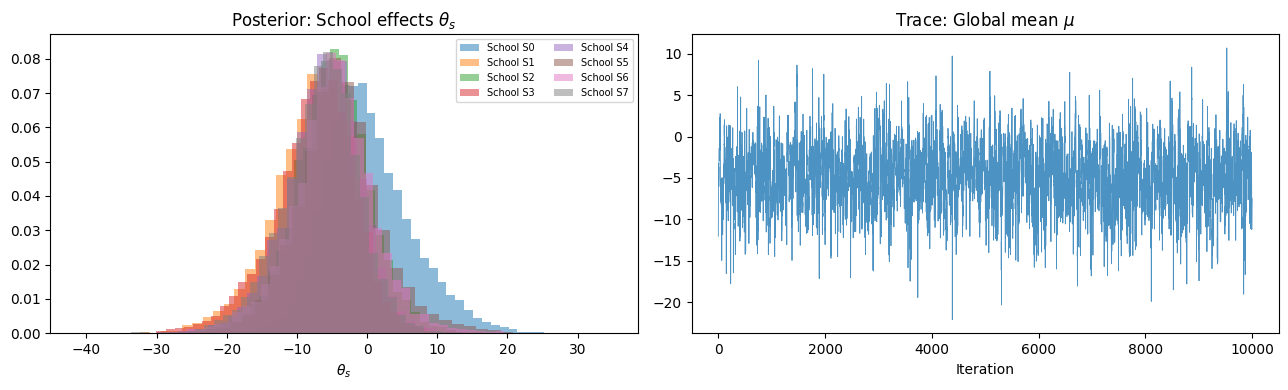

In [5]:
burnin = 1000
school_names = [f'S{i}' for i in range(S)]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

ax = axes[0]
for s in range(min(S, 8)):  # plot at most 8 schools to avoid clutter
    ax.hist(np.array(samples_seq[burnin:, s]), bins=40, alpha=0.5, density=True,
            label=f'School {school_names[s]}')
ax.set_title(r'Posterior: School effects $\theta_s$')
ax.set_xlabel(r'$\theta_s$')
ax.legend(fontsize=7, ncol=2)

ax = axes[1]
ax.plot(samples_seq[:, 2*S], alpha=0.8, linewidth=0.6)
ax.set_title(r'Trace: Global mean $\mu$')
ax.set_xlabel('Iteration')
plt.tight_layout()

## Jacobian structure

The Gibbs Jacobian should be approximately **rank-2** because the 8 school effects
$\theta_s$ are conditionally independent given the 2 shared hyperparameters $(\mu, \tau^2)$.
Coupling between time steps is mediated only through this rank-2 pathway.

Effective rank (>1% of sigma_1): 2
Top-5 singular values: [2.1299599e+01 1.1203601e+01 5.6085051e-03 2.7521951e-03 2.5811109e-03]


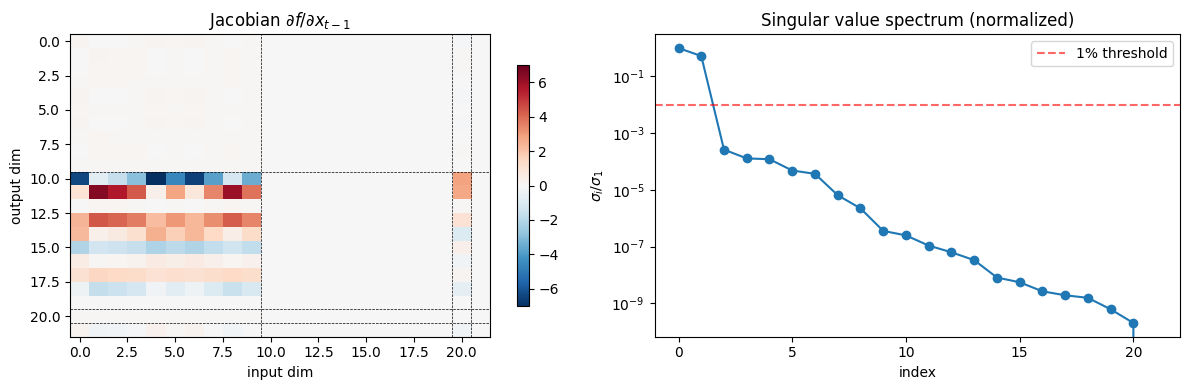

In [6]:
# Compute Jacobian at a typical state
typical_state  = samples_seq[250]
typical_driver = drivers[250]
J = jax.jacfwd(deer_fxn)(typical_state, typical_driver)

U, sv, Vt = jnp.linalg.svd(J)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

im = axes[0].imshow(J, aspect='auto', cmap='RdBu_r',
                    vmin=-jnp.abs(J).max(), vmax=jnp.abs(J).max())
axes[0].set_title(r'Jacobian $\partial f / \partial x_{t-1}$')
axes[0].set_xlabel('input dim'); axes[0].set_ylabel('output dim')
for pos in [S-0.5, 2*S-0.5, 2*S+0.5]:
    axes[0].axhline(pos, color='k', lw=0.5, ls='--')
    axes[0].axvline(pos, color='k', lw=0.5, ls='--')
plt.colorbar(im, ax=axes[0], shrink=0.8)

axes[1].semilogy(sv / sv[0], 'o-', markersize=6)
axes[1].axhline(0.01, color='red', ls='--', alpha=0.6, label='1% threshold')
axes[1].set_xlabel('index'); axes[1].set_ylabel(r'$\sigma_i / \sigma_1$')
axes[1].set_title('Singular value spectrum (normalized)')
axes[1].legend()

eff_rank = int((sv / sv[0] > 0.01).sum())
print(f"Effective rank (>1% of sigma_1): {eff_rank}")
print(f"Top-5 singular values: {sv[:5]}")

plt.tight_layout()

## Baseline convergence: DEER, quasi-DEER, Jacobi

In [7]:
# Shared setup for convergence experiments
x0_deer = init_state
guess   = jnp.broadcast_to(init_state, (L, D))
max_n   = 200
iters   = list(range(1, max_n + 1))

# All *_alg functions already compute merit at every iteration (7th return value).
# No need to recompute from all_states — just use mf_val directly.

# DEER baselines — single run each via full_trace
*_, deer_errs   = deer_alg(deer_fxn, x0_deer, guess, drivers, max_n, full_trace=True)
*_, quasi_errs  = deer_alg(deer_fxn, x0_deer, guess, drivers, max_n, quasi=True, full_trace=True)
*_, jacobi_errs = deer_alg(deer_fxn, x0_deer, guess, drivers, max_n, k=1, full_trace=True)

deer_errs   = list(np.array(deer_errs))
quasi_errs  = list(np.array(quasi_errs))
jacobi_errs = list(np.array(jacobi_errs))

In [8]:
# Iterations to convergence for each baseline
for name, kwargs in [("DEER (k=0)", {}),
                     ("quasi-DEER", dict(quasi=True)),
                     ("Jacobi (k=1)", dict(k=1))]:
    _, _, nb_iters, *_ = deer_alg(deer_fxn, x0_deer, guess, drivers,
                                   num_iters=max_n, tol=1e-2, **kwargs)
    print(f"{name}: converged in {int(nb_iters)} iterations")

DEER (k=0): converged in 9 iterations
quasi-DEER: converged in 87 iterations
Jacobi (k=1): converged in 99 iterations


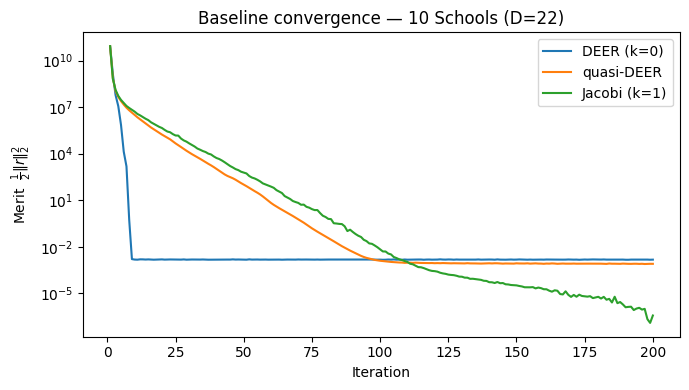

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))

ax.semilogy(iters, deer_errs,   label="DEER (k=0)")
ax.semilogy(iters, quasi_errs,  label="quasi-DEER")
ax.semilogy(iters, jacobi_errs, label="Jacobi (k=1)")

ax.set_xlabel("Iteration")
ax.set_ylabel(r"Merit  $\frac{1}{2}\|r\|_2^2$")
ax.set_title(f"Baseline convergence — {S} Schools (D={D})")
ax.legend()
plt.tight_layout()
plt.show()

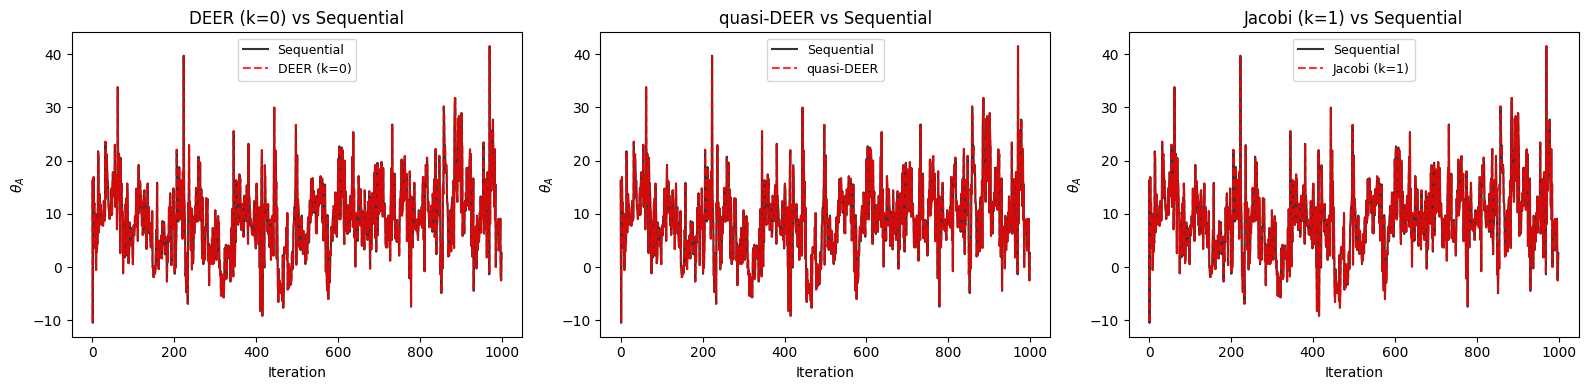

In [ ]:
# Compare converged trajectories to sequential Gibbs
_, deer_final, *_   = deer_alg(deer_fxn, x0_deer, guess, drivers, num_iters=max_n, tol=1e-2)
_, quasi_final, *_  = deer_alg(deer_fxn, x0_deer, guess, drivers, num_iters=max_n, tol=1e-2, quasi=True)
_, jacobi_final, *_ = deer_alg(deer_fxn, x0_deer, guess, drivers, num_iters=max_n, tol=1e-2, k=1)

# deer_alg returns (T, D) without x0 — prepend it
deer_sol   = jnp.vstack((x0_deer[None], deer_final))
quasi_sol  = jnp.vstack((x0_deer[None], quasi_final))
jacobi_sol = jnp.vstack((x0_deer[None], jacobi_final))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (name, sol) in zip(axes, [
    ("DEER (k=0)",    deer_sol),
    ("quasi-DEER",    quasi_sol),
    ("Jacobi (k=1)",  jacobi_sol),
]):
    ax.plot(samples_seq[:1000, 0], 'k-',  alpha=0.8, linewidth=1.5, label='Sequential')
    ax.plot(sol[1:1001,        0], 'r--', alpha=0.8, linewidth=1.5, label=name)
    ax.set_title(f'{name} vs Sequential')
    ax.set_xlabel('Iteration')
    ax.set_ylabel(r'$\theta_A$')
    ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

## Broyden-DEER convergence

Merit function vs Newton iterations for all Broyden init schemes at various window sizes `m`.

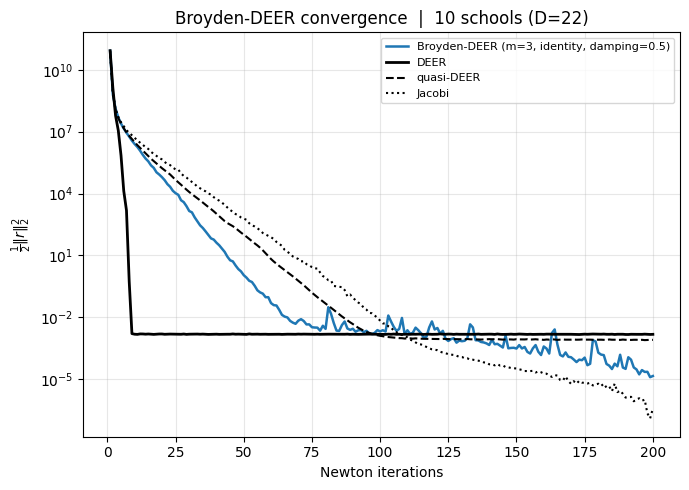

In [34]:
bd_m = 3
bd_init = "identity"
bd_damping = .5

*_, bd_errs = broyden_deer_alg(
    deer_fxn, x0_deer, guess, drivers, max_n,
    m=bd_m, init=bd_init, damping=bd_damping, full_trace=True, gamma=0.)
bd_errs = list(np.array(bd_errs))

fig, ax = plt.subplots(figsize=(7, 5))

ax.semilogy(iters, bd_errs, "-", color="tab:blue", linewidth=1.8,
            label=f"Broyden-DEER (m={bd_m}, {bd_init}, damping={bd_damping})")
ax.semilogy(iters, deer_errs,   "k-",  linewidth=2,   label="DEER")
ax.semilogy(iters, quasi_errs,  "k--", linewidth=1.5, label="quasi-DEER")
ax.semilogy(iters, jacobi_errs, "k:",  linewidth=1.5, label="Jacobi")
ax.set_xlabel("Newton iterations")
ax.set_ylabel(r"$\frac{1}{2}\|r\|_2^2$")
ax.set_title(f"Broyden-DEER convergence  |  {S} schools (D={D})")
ax.legend(fontsize=8); ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()

## Accelerated Broyden convergence

Merit function vs Newton iterations for all diagonal schemes at various ranks `k`.

In [1]:
acc_k = 2
acc_damping = .8
acc_init = "identity"
acc_eps_gram = 1e-6

*_, acc_errs = accelerated_broyden_deer_alg(
    deer_fxn, x0_deer, guess, drivers, max_n,
    k=acc_k, init=acc_init, damping=acc_damping, full_trace=True, eps_gram=acc_eps_gram, gamma=0.)
acc_errs = list(np.array(acc_errs))

fig, ax = plt.subplots(figsize=(7, 5))

ax.semilogy(iters, acc_errs, "-", color="tab:purple", linewidth=1.8,
            label=f"Accel. Broyden (k={acc_k}, damping={acc_damping}, {acc_init})")
ax.semilogy(iters, deer_errs,   "k-",  linewidth=2,   label="DEER")
ax.semilogy(iters, quasi_errs,  "k--", linewidth=1.5, label="quasi-DEER")
ax.semilogy(iters, jacobi_errs, "k:",  linewidth=1.5, label="Jacobi")
ax.set_xlabel("Newton iterations")
ax.set_ylabel(r"$\frac{1}{2}\|r\|_2^2$")
ax.set_title(f"Accelerated Broyden convergence  |  {S} schools (D={D})")
ax.legend(fontsize=8); ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()

NameError: name 'accelerated_broyden_deer_alg' is not defined

## Full-Broyden (global Woodbury) convergence

Merit function vs Newton iterations for all init schemes at various ranks `k`.

In [ ]:
fb_k_values    = [3, 5, 10]
fb_init_modes  = ["identity", "rescaled_identity", "jac", "fresh_jac"]
fb_styles      = {"identity": "--", "rescaled_identity": "-.", "jac": "-", "fresh_jac": ":"}
fb_colors      = {"identity": "tab:cyan", "rescaled_identity": "tab:olive",
                  "jac": "tab:green", "fresh_jac": "tab:red"}

fb_errs = {k: {} for k in fb_k_values}
for k in fb_k_values:
    for init_mode in fb_init_modes:
        *_, mf_val = full_broyden_deer_alg(
            deer_fxn, x0_deer, guess, drivers, max_n,
            k=k, init=init_mode, full_trace=True)
        fb_errs[k][init_mode] = list(np.array(mf_val))

fig, axes = plt.subplots(1, len(fb_k_values), figsize=(5 * len(fb_k_values), 5), sharey=True)

for ax, k in zip(axes, fb_k_values):
    for init_mode in fb_init_modes:
        ax.semilogy(iters, fb_errs[k][init_mode], fb_styles[init_mode],
                    color=fb_colors[init_mode], label=f'{init_mode}', linewidth=1.8)
    ax.semilogy(iters, deer_errs,   "k-",  linewidth=2,   label="DEER")
    ax.semilogy(iters, quasi_errs,  "k--", linewidth=1.5, label="quasi-DEER")
    ax.semilogy(iters, jacobi_errs, "k:",  linewidth=1.5, label="Jacobi")
    ax.set_xlabel("Newton iterations")
    ax.set_title(f"Full-Broyden k={k}")
    ax.legend(fontsize=8); ax.grid(True, which="both", alpha=0.3)

axes[0].set_ylabel(r"$\frac{1}{2}\|r\|_2^2$")
fig.suptitle(f"Full-Broyden (global Woodbury) convergence  |  {S} schools (D={D})", y=1.02)
plt.tight_layout()